In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy import random
from scipy.stats import uniform
from scipy.stats import norm
from scipy.stats import uniform
from scipy.stats import t


df = pd.read_csv(r"C:\Users\Adria\Desktop\Quant\polish-bank-risk-monitor\data\raw\pko.csv")
print(df.shape)
print(df.columns.tolist())
df.head(3)

(1523, 6)
['Data', 'Otwarcie', 'Najwyzszy', 'Najnizszy', 'Zamkniecie', 'Wolumen']


,Data,Otwarcie,Najwyzszy,Najnizszy,Zamkniecie,Wolumen
0,2020-10-01,16.3101,16.3254,15.9831,16.0364,1.856062e+06
1,2020-10-02,15.8159,16.3634,15.7703,16.2112,1.709034e+06
2,2020-10-05,16.3862,16.6751,16.3406,16.6675,2.482573e+06


In [2]:
def plot_pdf_cdf(dist,x_min,x_max,title) -> plt.Figure:
    
    x = np.linspace(x_min,x_max,500)
    
    fig,axes = plt.subplots(1,2, figsize = (11,5))
    axes[0].plot(x, dist.pdf(x))
    axes[0].set_title("PDF")
    axes[0].set_xlabel("x")

    axes[1].plot(x,dist.cdf(x))
    axes[1].set_title("CDF")
    axes[1].set_xlabel("x")
    fig.suptitle(title)
    fig.tight_layout()
    return fig    

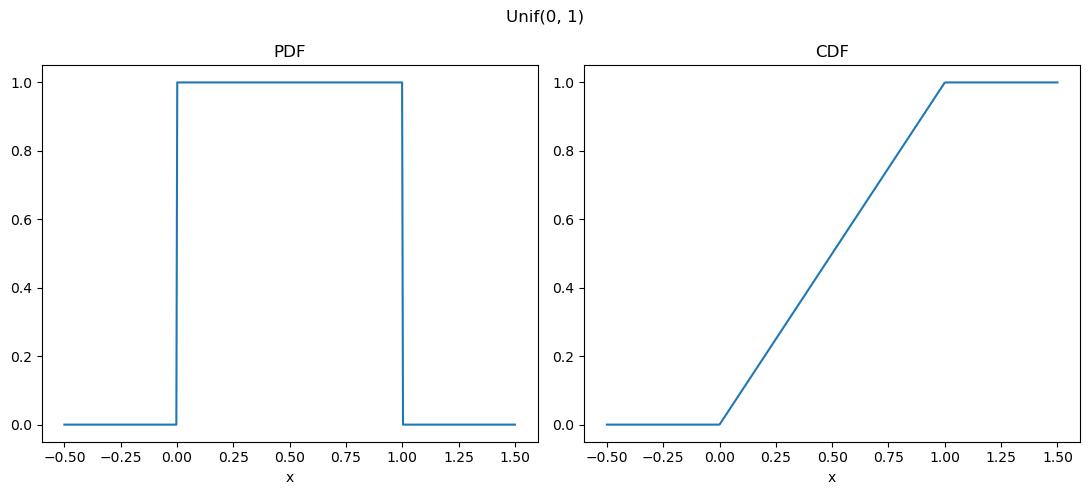

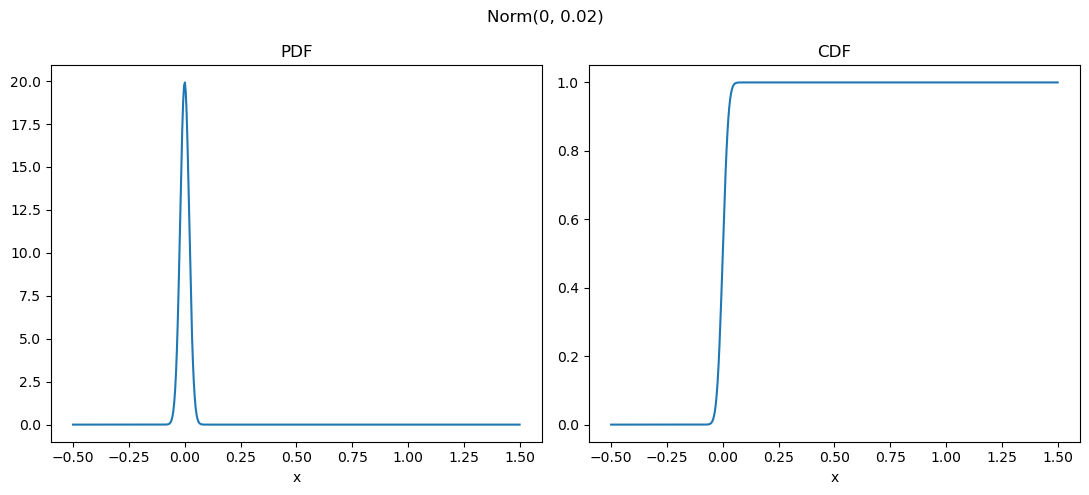

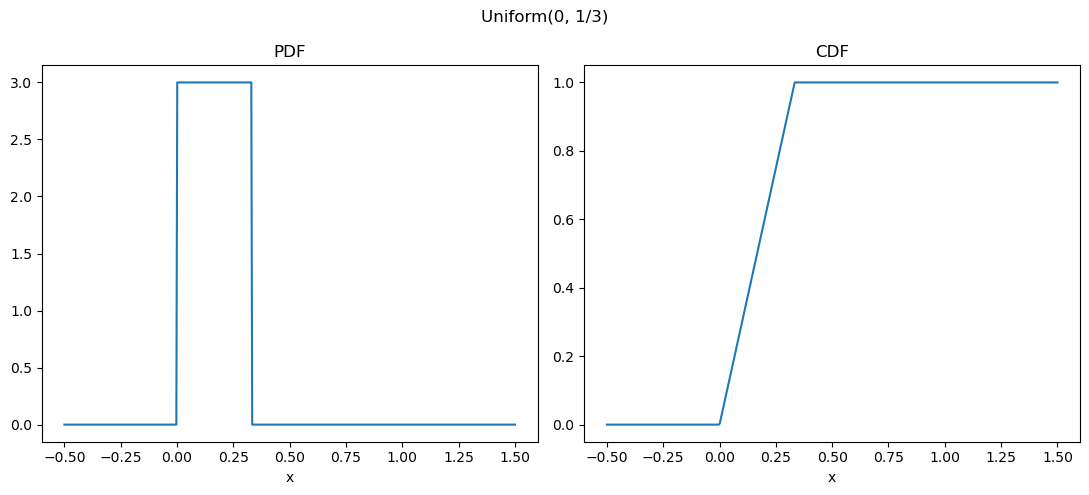

In [3]:
fig_unif = plot_pdf_cdf(uniform(0, 1), -0.5, 1.5, "Unif(0, 1)")
fig_norm = plot_pdf_cdf(norm(0, 0.02), -0.5, 1.5, "Norm(0, 0.02)")
fig_norm_2 = plot_pdf_cdf(uniform(0, 1/3), -0.5, 1.5, "Uniform(0, 1/3)")

In [4]:
returns = np.log(df["Zamkniecie"]).diff().dropna()
returns_mean = returns.mean()
returns_std = returns.std()

print(f"Mean daily return: {returns_mean:.4%}")
print(f"Std of daily returns: {returns_std:.4%}")

Mean daily return: 0.1292%
Std of daily returns: 2.1506%


<Axes: >

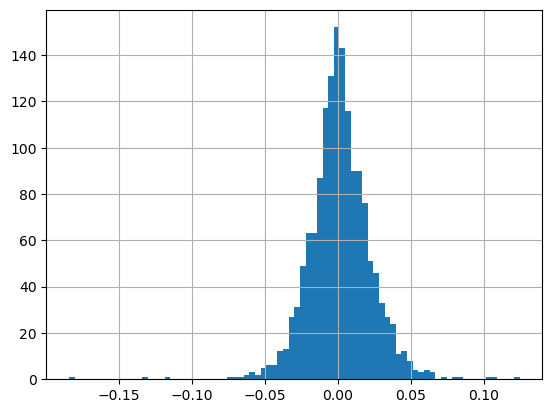

In [5]:
returns.hist(bins=80)

<Axes: >

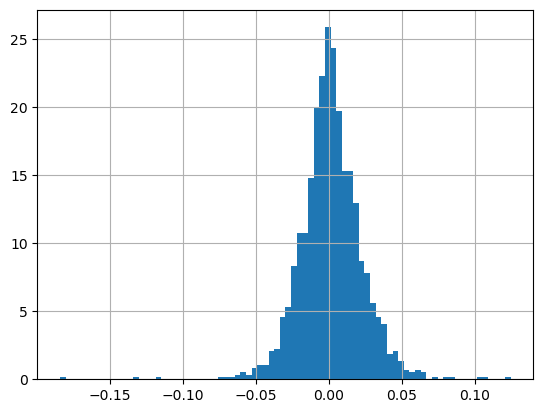

In [6]:
returns.hist(bins=80, density = True)


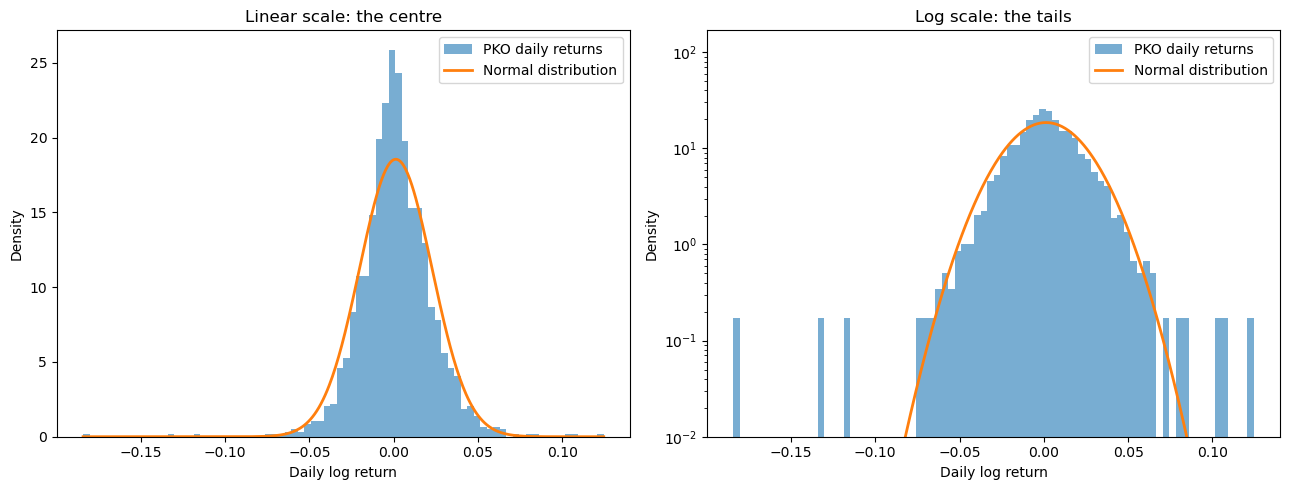

In [7]:
normal = norm(returns_mean, returns_std)
x = np.linspace(returns.min(), returns.max(), 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax in axes:
    ax.hist(returns, bins=80, density=True, alpha=0.6, label="PKO daily returns")
    ax.plot(x, normal.pdf(x), linewidth=2, label="Normal distribution")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.legend()

axes[0].set_title("Linear scale: the centre")
axes[1].set_title("Log scale: the tails")
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=1e-2)

fig.tight_layout()
plt.show()

In [8]:
returns_df = returns.sort_values()

In [9]:
returns_df = pd.DataFrame(returns.sort_values()).reset_index(drop=True).rename(columns = {"Zamkniecie":"sort"}).reset_index()
returns_df["index"] +=1
returns_df["empirical_distr"] = returns_df["index"]/len(returns_df)

In [10]:
print(returns_df["empirical_distr"].iloc[0], returns_df["empirical_distr"].iloc[-1])

0.000657030223390276 1.0


In [11]:
returns_df

,index,sort,empirical_distr
0,1,-0.184172,0.000657
1,2,-0.130432,0.001314
2,3,-0.116046,0.001971
3,4,-0.074546,0.002628
4,5,-0.069266,0.003285
...,...,...,...
1517,1518,0.081801,0.997372
1518,1519,0.084304,0.998029
1519,1520,0.102608,0.998686
1520,1521,0.106656,0.999343


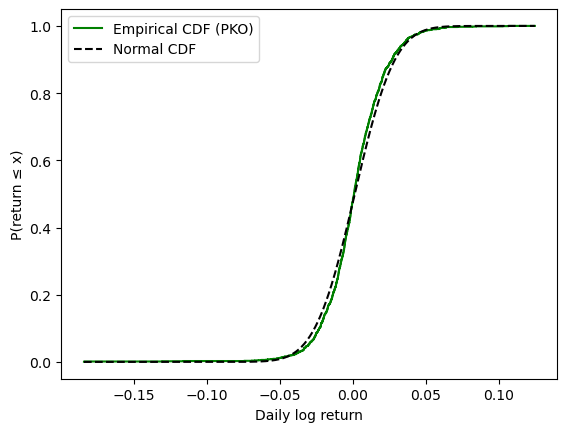

In [12]:
x = returns_df["sort"]
y = returns_df["empirical_distr"]

fig, ax = plt.subplots()
ax.step(x, y, color="green", label="Empirical CDF (PKO)")
x_grid = np.linspace(x.min(), x.max(), 500)
ax.plot(x_grid, normal.cdf(x_grid), color="black", linestyle="--", label="Normal CDF")
ax.set_xlabel("Daily log return")
ax.set_ylabel("P(return ≤ x)")
ax.legend()
plt.show()

In [13]:
## T student

t_df, t_loc, t_scale = t.fit(returns)
student = t(t_df, t_loc, t_scale)

print(f"Degrees of freedom: {t_df:.2f}")

Degrees of freedom: 4.95


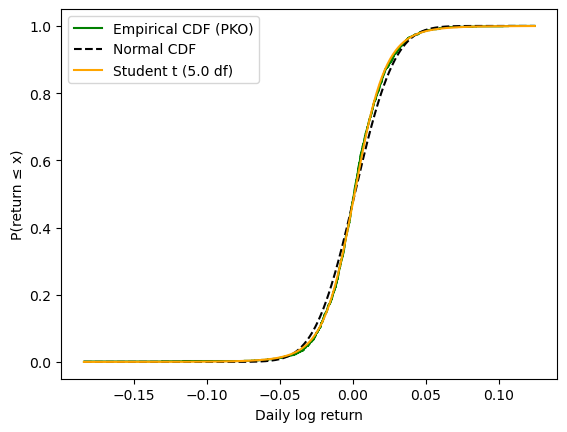

In [14]:
x = returns_df["sort"]
y = returns_df["empirical_distr"]

fig, ax = plt.subplots()
ax.step(x, y, color="green", label="Empirical CDF (PKO)")
x_grid = np.linspace(x.min(), x.max(), 500)
ax.plot(x_grid, normal.cdf(x_grid), color="black", linestyle="--", label="Normal CDF")
ax.plot(x_grid, student.cdf(x_grid), color="orange", label=f"Student t ({t_df:.1f} df)")
ax.set_xlabel("Daily log return")
ax.set_ylabel("P(return ≤ x)")
ax.legend()
plt.show()

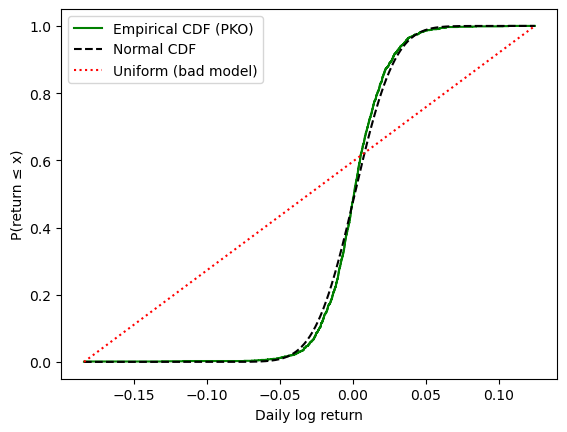

In [15]:
x = returns_df["sort"]
y = returns_df["empirical_distr"]
bad = uniform(loc=returns.min(), scale=returns.max() - returns.min())

fig, ax = plt.subplots()
ax.step(x, y, color="green", label="Empirical CDF (PKO)")
x_grid = np.linspace(x.min(), x.max(), 500)
ax.plot(x_grid, normal.cdf(x_grid), color="black", linestyle="--", label="Normal CDF")
ax.plot(x_grid, bad.cdf(x_grid), color="red", linestyle=":", label="Uniform (bad model)")
ax.set_xlabel("Daily log return")
ax.set_ylabel("P(return ≤ x)")
ax.legend()
plt.show()

## Sampling via inverse CDF

In [51]:
seed = 42
number_count = 100_00
rng = np.random.default_rng(seed)
u = rng.random(number_count)
normal = norm(returns_mean,returns_std)
simulated = normal.ppf(u)

In [57]:
sim_mean = simulated.mean() 
sim_std = simulated.std()
print(f"Mean   | data: {returns_mean:.4%} | simulated: {sim_mean:.4%} | diff: {sim_mean - returns_mean:+.4%}")
print(f"Std    | data: {returns_std:.4%} | simulated: {sim_std:.4%} | diff: {sim_std - returns_std:+.4%}")

Mean   | data: 0.1292% | simulated: 0.1121% | diff: -0.0171%
Std    | data: 2.1506% | simulated: 2.1510% | diff: +0.0003%


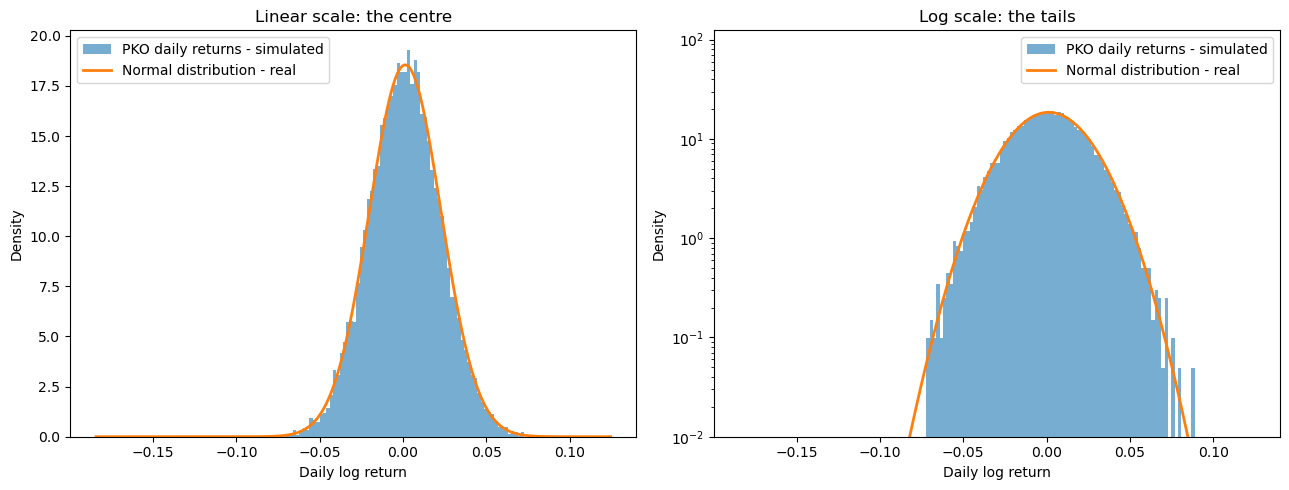

In [59]:
normal = norm(returns_mean, returns_std)
x = np.linspace(returns.min(), returns.max(), 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax in axes:
    ax.hist(simulated, bins=80, density=True, alpha=0.6, label="PKO daily returns - simulated")
    ax.plot(x, normal.pdf(x), linewidth=2, label="Normal distribution - real")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.legend()

axes[0].set_title("Linear scale: the centre")
axes[1].set_title("Log scale: the tails")
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=1e-2)

fig.tight_layout()
plt.show()

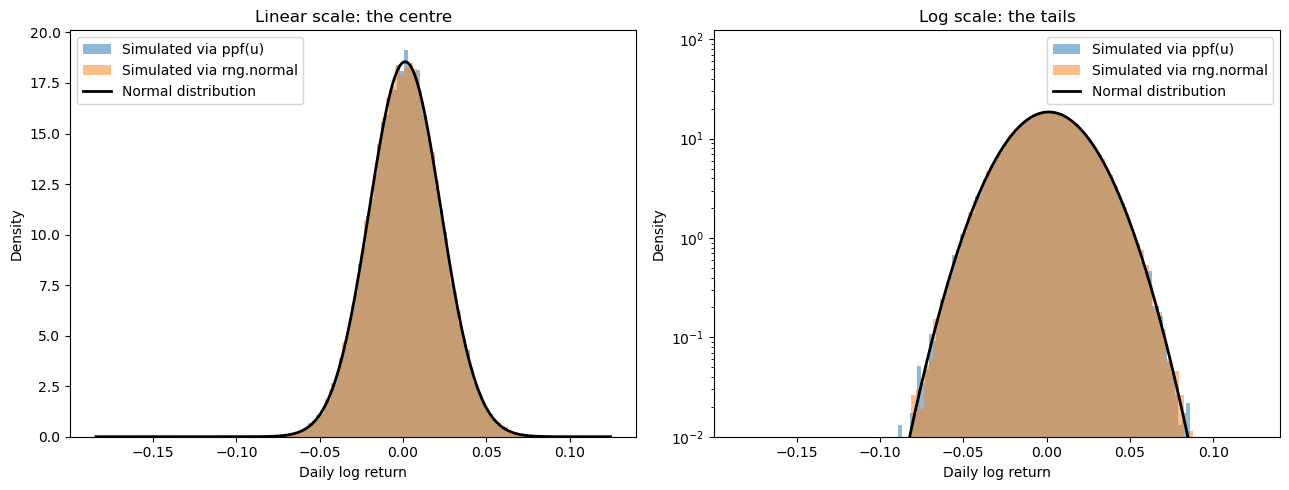

ppf(u)     | mean: 0.1324% | std: 2.1520%
rng.normal | mean: 0.1351% | std: 2.1543%
target     | mean: 0.1292% | std: 2.1506%


In [85]:
normal = norm(returns_mean, returns_std)
x = np.linspace(returns.min(), returns.max(), 500)

rng = np.random.default_rng(42)
u = rng.random(100_000)
sim_ppf = normal.ppf(u)                                        # method 1
sim_rng_normal = rng.normal(returns_mean, returns_std, 100_000)  # metthod 2: wbudowane losowanie

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax in axes:
    ax.hist(sim_ppf, bins=80, density=True, alpha=0.5, label="Simulated via ppf(u)")
    ax.hist(sim_rng_normal, bins=80, density=True, alpha=0.5, label="Simulated via rng.normal")
    ax.plot(x, normal.pdf(x), color="black", linewidth=2, label="Normal distribution")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.legend()

axes[0].set_title("Linear scale: the centre")
axes[1].set_title("Log scale: the tails")
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=1e-2)

fig.tight_layout()
plt.show()

print(f"ppf(u)     | mean: {sim_ppf.mean():.4%} | std: {sim_ppf.std():.4%}")
print(f"rng.normal | mean: {sim_rng_normal.mean():.4%} | std: {sim_rng_normal.std():.4%}")
print(f"target     | mean: {returns_mean:.4%} | std: {returns_std:.4%}")

In [73]:
## T - student
t_df, t_loc, t_scale = t.fit(returns)
student = t(t_df, t_loc, t_scale)

simulated_student = student.ppf(u)

In [75]:
sim_mean = student.mean() 
sim_std = student.std()
print(f"Mean   | data: {returns_mean:.4%} | simulated: {sim_mean:.4%} | diff: {sim_mean - returns_mean:+.4%}")
print(f"Std    | data: {returns_std:.4%} | simulated: {sim_std:.4%} | diff: {sim_std - returns_std:+.4%}")

Mean   | data: 0.1292% | simulated: 0.1073% | diff: -0.0219%
Std    | data: 2.1506% | simulated: 2.1251% | diff: -0.0256%


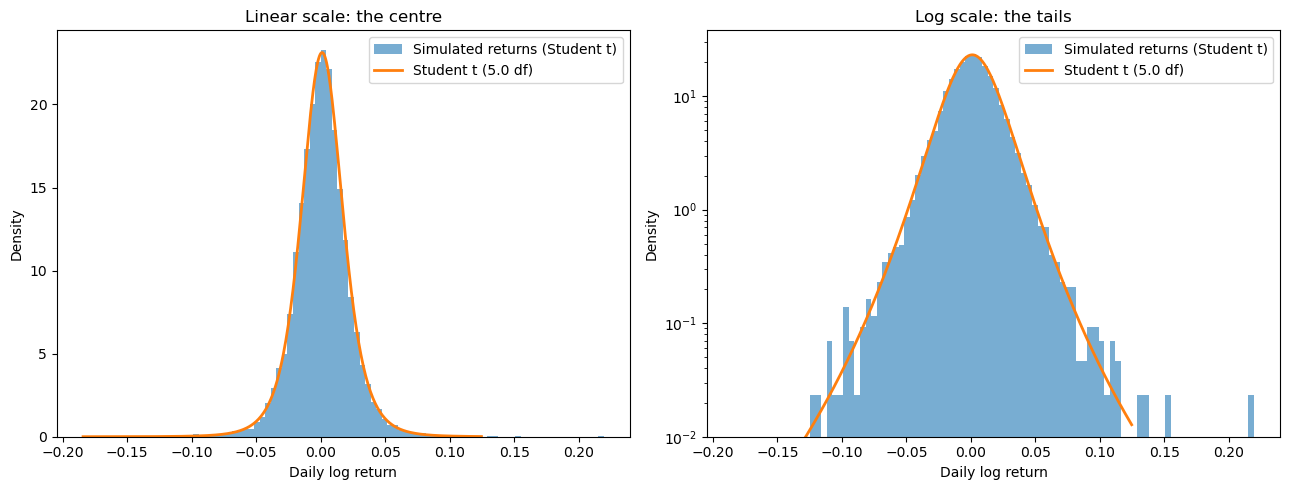

In [83]:
normal = norm(returns_mean, returns_std)
x = np.linspace(returns.min(), returns.max(), 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax in axes:
    ax.hist(simulated_student, bins=80, density=True, alpha=0.6, label="Simulated returns (Student t)")
    ax.plot(x, student.pdf(x), linewidth=2, label=f"Student t ({t_df:.1f} df)")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.legend()

axes[0].set_title("Linear scale: the centre")
axes[1].set_title("Log scale: the tails")
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=1e-2)

fig.tight_layout()
plt.show()

In [87]:
Monte Carlo VaR. Z obu symulacji policz kwantyl 1% (dzienny VaR 99%) i dopisz do tabeli z wtorku:
Metoda    Dzienny VaR 99%
historyczny (z danych)    z wtorku
normalny, ze wzoru (ppf(0.01))    z wtorku
normalny, Monte Carlo    nowe
t-Studenta, Monte Carlo    nowe

SyntaxError: invalid syntax (820169564.py, line 1)

In [89]:
krok 6 (bonus): prawdziwe zwroty przepuszczone przez cdf rozkładu normalnego i rozkładu t, z histogramami wyników. Sprawdzasz, który model daje bardziej płaski histogram

SyntaxError: invalid syntax (2805139845.py, line 1)